# ☕ Proyecto **Centinela** · Fase 1 — *Centinela del Café*: línea base con un MLP
### Profundización I: Redes Neuronales — Deep Learning (EA-N-F-004) · Maestría en Ciencia de Datos · Universidad Santo Tomás

**Autor:** Julio César González R. · **Modalidad:** individual · **Fecha:** 2026-10-30

**Pregunta del cliente.** ¿Puede un modelo sencillo avisar, a partir de una foto de la hoja, si una planta de café robusta está enferma (roya o ácaro rojo), para que el técnico de campo priorice la inspección y el tratamiento?

**Qué hace este cuaderno, en orden:**

| Sección | Qué se hace | Criterio de la rúbrica |
|---|---|---|
| 0 | Entorno, semillas y rutas | C2 |
| 1 | Descarga trazable desde las fuentes primarias, con huella SHA-256 | C1 |
| 2 | Huella de crudeza y minimización (se descartan columnas con datos personales) | C1 |
| 3 | De la imagen a la tabla: rasgos de color y textura dentro de la hoja | C1 |
| 4 | EDA: cada hallazgo termina en una decisión | C1 |
| 5 | Partición por planta y escalado sin fuga | C1 |
| 6 | Línea base comprometida: clase mayoritaria y escalar crudo | C1, C4 |
| 7 | Arquitectura del MLP (salida en *logit*) | C2 |
| 8 | Bucle de entrenamiento explícito, curvas y comparación de capacidad | C2, C3 |
| 9 | Sobreajuste inducido y corregido con *Dropout* | C3 |
| 10 | Umbral en validación, evaluación única en prueba, errores y ética | C4 |
| 11 | Prueba de acoplamiento imagen ↔ clima (anexo A de la Propuesta) | C1 |
| 12 | Auditoría a la IA: el listado truncado de Mendeley, reproducido | C5 |
| 13 | Cifras para el informe | C6 |

> **Cómo correrlo:** *Entorno de ejecución → Ejecutar todo*. La primera vez descarga ≈ 700 MB desde Mendeley Data y extrae los rasgos (≈ 10–15 min en Colab con CPU). Las siguientes veces reutiliza la tabla de rasgos guardada en Google Drive.

## 0. Preparación del entorno

Se fijan **tres semillas** (Python, NumPy y PyTorch): si una queda suelta, las curvas cambian entre ejecuciones y no se pueden comparar las corridas. Los datos se guardan en Google Drive cuando el cuaderno corre en Colab, para no volver a descargar ni a extraer rasgos si la máquina virtual se recicla.

In [1]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda 0 · Entorno, semillas y rutas
# Qué hace · Importa librerías, fija semillas, define rutas (Drive en Colab, carpeta local fuera de Colab).
# Por qué  · Reproducibilidad: misma semilla ⇒ misma partición y mismas curvas (punto de comparación de la Fase 2).
import os, io, re, json, copy, time, random, shutil, hashlib, tarfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import torch
import torch.nn as nn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, precision_recall_fscore_support,
                             accuracy_score, roc_auc_score)

SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
torch.use_deterministic_algorithms(True, warn_only=True)

try:                                   # en Colab: datos y puntos de control en Drive
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/centinela_fase1"
    TEMP = "/content/tmp_centinela"     # el .tar.gz grande va al disco temporal, no a Drive
except ImportError:                    # fuera de Colab: carpeta local
    BASE = os.environ.get("CENTINELA_BASE", "centinela_fase1")
    TEMP = os.path.join(BASE, "tmp")
DATOS = os.path.join(BASE, "datos"); os.makedirs(DATOS, exist_ok=True); os.makedirs(TEMP, exist_ok=True)

COLOR_SANA, COLOR_ENF, COLOR_GRIS = "#1b6e3a", "#b5532a", "#7a7a7a"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("torch", torch.__version__, "| datos en:", DATOS)

Mounted at /content/drive
torch 2.11.0+cpu | datos en: /content/drive/MyDrive/centinela_fase1/datos


## 1. Descarga trazable desde las fuentes primarias

Las dos fuentes de la Propuesta de Datos aprobada, **descargadas de su productor primario** (sin réplicas de terceros):

| Modalidad | Fuente primaria | Qué se descarga | Licencia |
|---|---|---|---|
| Imagen | RoCoLe v2 (Mendeley Data, DOI 10.17632/c5yvn32dzg.2) | `RoCoLE-csv.csv` (etiquetas y polígono de la hoja) y `RoCoLe-voc.tar.gz` (las 1.560 fotos) | CC BY 4.0 |
| Serie temporal | NASA POWER, API mensual por coordenadas (Calceta, Manabí: −0,8342; −80,1772) | T2M, T2M_MAX, T2M_MIN, RH2M, PRECTOTCORR, 2017–2019 | Datos NASA de libre uso |

Cada archivo de Mendeley se consulta en la **API pública del repositorio**, que publica su huella SHA-256; el cuaderno la **recalcula** sobre el archivo descargado y comprueba que coincidan (cadena de procedencia, anexo B de la Propuesta).

> **Por qué el `.tar.gz` VOC y no la carpeta `Photos`:** la API de Mendeley lista como máximo 1.000 archivos por carpeta (`content-range: items 0-999/1560`) y no acepta paginación. Descargar la carpeta `Photos` archivo por archivo pierde en silencio 560 fotos. El paquete VOC trae las 1.560 en un solo archivo verificable. Es el fallo de IA documentado en la sección 12.

La respuesta de NASA POWER incluye tiempos de proceso que cambian en cada consulta, así que su huella se calcula sobre el **bloque de datos** (`properties.parameter`, serializado con claves ordenadas), que sí es estable.

In [2]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda 1 · Descarga trazable + huella SHA-256
# Qué hace · Consulta la API de Mendeley (URL y SHA-256 publicados), descarga, recalcula la huella y compara.
#            Descarga el clima mensual de NASA POWER y calcula la huella de su bloque de datos.
# Por qué  · Test de procedencia (anexo B): productor primario, fecha, nombre exacto y huella de cada archivo.
MENDELEY_API = "https://data.mendeley.com/public-api/datasets/c5yvn32dzg"
CARPETA_ANOTACIONES = "201c7329-268c-48fb-a452-d9b435817774"   # carpeta «Annotations» de RoCoLe v2
ARCHIVOS = {"RoCoLE-csv.csv": DATOS, "RoCoLe-voc.tar.gz": TEMP}   # E-2: paquete VOC (1.560 fotos), no la carpeta Photos
VERIFICAR_HUELLA = True

def sha256_archivo(ruta, bloque=2**22):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()

# Mendeley está detrás de Cloudflare, que rechaza (403) el agente por defecto de Python: se envía uno de navegador.
CABECERAS = {"User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) "
                           "Chrome/126.0 Safari/537.36", "Accept": "application/json, */*"}

def abrir(url, timeout=120):
    return urllib.request.urlopen(urllib.request.Request(url, headers=CABECERAS), timeout=timeout)

def leer_json(url):
    with abrir(url) as r:
        return json.load(r)

def descargar(url, ruta):
    parcial = ruta + ".parcial"
    with abrir(url, timeout=900) as r, open(parcial, "wb") as f:
        shutil.copyfileobj(r, f, 2**22)
    os.replace(parcial, ruta)

# Respaldo: metadatos publicados por la API de Mendeley, consultados el 2026-10-30 (anexo B de la Propuesta)
RESPALDO_MENDELEY = {
    "RoCoLE-csv.csv": {"size": 2220101,
        "download_url": "https://data.mendeley.com/public-files/datasets/c5yvn32dzg/files/e39cecdd-8dca-445a-b734-10229427f2fa/file_downloaded",
        "sha256_hash": "a9aa6b411569dba7e9ba56fed79e5cd82af04a0ef092e56309158d632ac5205b"},
    "RoCoLe-voc.tar.gz": {"size": 697591506,
        "download_url": "https://data.mendeley.com/public-files/datasets/c5yvn32dzg/files/3cfa348c-179b-4f05-9a6d-6c9343dd5c03/file_downloaded",
        "sha256_hash": "7b45c70c5a1e4270ff456ab95d07dca2c6533d15954015ba0261cdcdc016b485"}}

try:
    listado = leer_json(f"{MENDELEY_API}/files?version=2&folder_id={CARPETA_ANOTACIONES}")
    metadatos = {f["filename"]: f["content_details"] for f in listado}
    origen_meta = "API de Mendeley (en vivo)"
except Exception as e:
    print(f"Aviso: la API de Mendeley no respondió ({e}); se usan los metadatos registrados el 2026-10-30.")
    metadatos, origen_meta = RESPALDO_MENDELEY, "metadatos registrados 2026-10-30"

procedencia = []
for nombre, carpeta in ARCHIVOS.items():
    meta = metadatos[nombre]
    ruta = os.path.join(carpeta, nombre)
    if not os.path.exists(ruta) and os.path.exists(os.path.join(DATOS, nombre)):
        ruta = os.path.join(DATOS, nombre)             # copia subida a mano a Drive (plan B)
    if not os.path.exists(ruta):
        print(f"Descargando {nombre} ({meta['size']/1e6:.1f} MB)…")
        try:
            descargar(meta["download_url"], ruta)
        except Exception as e:
            raise RuntimeError(
                f"No se pudo descargar {nombre} ({e}). Plan B: descárgalo a mano desde "
                "https://data.mendeley.com/datasets/c5yvn32dzg/2 (carpeta Annotations), súbelo a "
                f"Google Drive en {DATOS} y vuelve a ejecutar esta celda.") from None
    huella = sha256_archivo(ruta)
    if VERIFICAR_HUELLA and huella != meta["sha256_hash"]:
        raise ValueError(f"La huella de {nombre} no coincide con la publicada por Mendeley")
    procedencia.append({"archivo": nombre, "productor": "Mendeley Data · RoCoLe v2",
                        "url": meta["download_url"], "sha256_publicada": meta["sha256_hash"],
                        "sha256_calculada": huella, "coincide": huella == meta["sha256_hash"],
                        "fecha_descarga": time.strftime("%Y-%m-%d", time.localtime(os.path.getmtime(ruta)))})
print("Huellas publicadas tomadas de:", origen_meta)

# NASA POWER: clima mensual en la celda de la finca experimental (CIIDEA-ESPAM, Calceta, Manabí)
LAT, LON = -0.8342, -80.1772
URL_POWER = ("https://power.larc.nasa.gov/api/temporal/monthly/point?"
             "parameters=T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR&community=AG"
             f"&longitude={LON}&latitude={LAT}&start=2017&end=2019&format=JSON")
RUTA_POWER = os.path.join(DATOS, "nasa_power_calceta_2017_2019.json")
if not os.path.exists(RUTA_POWER):
    descargar(URL_POWER, RUTA_POWER)
power = json.load(open(RUTA_POWER))
bloque = json.dumps(power["properties"]["parameter"], sort_keys=True, separators=(",", ":"))   # E-5
procedencia.append({"archivo": "nasa_power_calceta_2017_2019.json", "productor": "NASA POWER (API v2, mensual)",
                    "url": URL_POWER, "sha256_publicada": "—",
                    "sha256_calculada": hashlib.sha256(bloque.encode()).hexdigest() + " (bloque de datos)",
                    "coincide": None,
                    "fecha_descarga": time.strftime("%Y-%m-%d", time.localtime(os.path.getmtime(RUTA_POWER)))})
pd.set_option("display.max_colwidth", 70)
pd.DataFrame(procedencia)[["archivo", "productor", "fecha_descarga", "sha256_calculada", "coincide"]]

Descargando RoCoLe-voc.tar.gz (697.6 MB)…
Huellas publicadas tomadas de: API de Mendeley (en vivo)


,archivo,productor,fecha_descarga,sha256_calculada,coincide
0,RoCoLE-csv.csv,Mendeley Data · RoCoLe v2,2026-10-31,a9aa6b411569dba7e9ba56fed79e5cd82af04a0ef092e56309158d632ac5205b,True
1,RoCoLe-voc.tar.gz,Mendeley Data · RoCoLe v2,2026-10-31,7b45c70c5a1e4270ff456ab95d07dca2c6533d15954015ba0261cdcdc016b485,True
2,nasa_power_calceta_2017_2019.json,"NASA POWER (API v2, mensual)",2026-10-31,02da8ae0bf87836b17d02cd30c41a7b696f3815a4494dbf77ed4e55662ebf235 (...,None


## 2. Huella de crudeza y minimización de datos

Antes de limpiar se mide el archivo **tal como llega** (filas × columnas, faltantes, balance). Luego se aplica la **minimización** de la Ley 1581 de 2012: el CSV de Labelbox trae columnas que **no** se necesitan y una de ellas es un **dato personal** de un tercero (`Created By`, el correo de quien anotó). Se descartan **antes de mostrar cualquier fila**; el cuaderno nunca imprime esas columnas.

In [3]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda 2 · Huella de crudeza (antes de limpiar) y minimización
# Qué hace · Mide el CSV crudo, descarta columnas personales o innecesarias y construye la etiqueta binaria.
# Por qué  · Anexo B (huella de crudeza) y anexo C (minimización, Ley 1581 art. 4 y DUR 2.2.2.25.2.1).
crudo = pd.read_csv(os.path.join(DATOS, "RoCoLE-csv.csv"))
faltantes = crudo.isna().mean().mul(100).round(1)
print(f"Forma cruda: {crudo.shape[0]} filas × {crudo.shape[1]} columnas")
print(f"Faltantes globales: {crudo.isna().mean().mean()*100:.1f} % de las celdas")
print("Columnas con faltantes (%):", faltantes[faltantes > 0].to_dict())

COLUMNAS_PERSONALES = ["Created By"]                         # E-3: correo del anotador → dato personal
COLUMNAS_INNECESARIAS = ["DataRow ID", "Labeled Data", "Project Name", "Created At", "Updated At",
                         "Seconds to Label", "Agreement", "Benchmark Agreement", "Benchmark ID",
                         "Benchmark Reference ID", "Dataset Name", "Reviews", "View Label", "Masks"]
etiquetas = crudo.drop(columns=COLUMNAS_PERSONALES + COLUMNAS_INNECESARIAS).rename(
    columns={"ID": "id", "External ID": "archivo", "Label": "label_json"})
del crudo                                                     # no queda copia con el dato personal

lab = etiquetas["label_json"].apply(json.loads)
etiquetas["clase6"] = lab.apply(lambda d: d["classification"])        # 6 clases originales
etiquetas["poligonos"] = lab.apply(lambda d: [[(p["x"], p["y"]) for p in hoja["geometry"]] for hoja in d.get("Leaf", [])])
etiquetas["y"] = (etiquetas["clase6"] != "healthy").astype(int)        # 1 = enferma (roya o ácaro)
m = etiquetas["archivo"].str.extract(r"^C(\d+)P(\d+)")
etiquetas["planta"] = "C" + m[0] + "P" + m[1]                          # 390 plantas del lote experimental
irregulares = etiquetas.loc[~etiquetas["archivo"].str.match(r"^C\d+P\d+[HE]\d+\.jpg$"), "archivo"].tolist()
etiquetas = etiquetas.drop(columns="label_json")

print(f"\nNombres de archivo irregulares: {irregulares}")
print(f"Plantas distintas: {etiquetas['planta'].nunique()} | hojas por planta (mediana): "
      f"{etiquetas.groupby('planta').size().median():.0f}")
print("\nClases originales (6):"); print(etiquetas["clase6"].value_counts().to_string())
print("\nEtiqueta binaria:"); print(etiquetas["y"].map({0: "sana", 1: "enferma"}).value_counts().to_string())
etiquetas[["id", "archivo", "planta", "clase6", "y"]].head()

Forma cruda: 1560 filas × 18 columnas
Faltantes globales: 22.2 % de las celdas
Columnas con faltantes (%): {'Agreement': 99.0, 'Benchmark Agreement': 100.0, 'Benchmark ID': 100.0, 'Benchmark Reference ID': 100.0}

Nombres de archivo irregulares: ['C11P11HE.jpg']
Plantas distintas: 390 | hojas por planta (mediana): 4

Clases originales (6):
clase6
healthy            791
rust_level_1       344
red_spider_mite    167
rust_level_2       166
rust_level_3        62
rust_level_4        30

Etiqueta binaria:
y
sana       791
enferma    769


,id,archivo,planta,clase6,y
0,cjvnf5ealftjc0984n8uka3fs,C1P1H1.jpg,C1P1,healthy,0
1,cjvnf878wfzzd0838svwmv6gu,C1P2E2.jpg,C1P2,rust_level_2,1
2,cjvnf89dsfy900795gjew8qoj,C1P2H1.jpg,C1P2,healthy,0
3,cjvnf8b7fg82s0a70ijp6fz1o,C1P3E1.jpg,C1P3,healthy,0
4,cjvnf8dd6fz1s0828a8zwknn1,C1P3E2.jpg,C1P3,rust_level_2,1


## 3. De la imagen a la tabla: rasgos dentro de la hoja

La Fase 1 trabaja con la **versión tabular de la modalidad imagen**. Cada foto se resume en 14 números, calculados **solo dentro del polígono de la hoja** que anotaron los autores (el fondo —suelo, otras hojas, cielo— cambia de foto a foto y sería ruido o, peor, un atajo):

| Grupo | Rasgos | Qué capta |
|---|---|---|
| Color medio y dispersión | `r_media, g_media, b_media, r_desv, g_desv, b_desv` | El verde sano frente a las manchas amarillo-naranja |
| Espacio HSV | `matiz_medio, saturacion_media, brillo_medio` | Color separado de la iluminación |
| Índices derivados | `exg_medio` (exceso de verde, 2g − r − b) | Vigor del tejido verde |
| Proporciones de píxeles | `frac_roya` (matiz 10°–50°, saturado) · `frac_oscuro` (brillo < 0,2) | Área con síntoma de roya o necrosis |
| Textura | `textura` (magnitud media del gradiente en gris) | Pústulas y manchas rompen la superficie lisa |
| Forma | `area_hoja` (fracción de la foto ocupada por la hoja) | Distancia y encuadre (control) |

Cada imagen se decodifica a ≈ ¼ de su tamaño (`Image.draft`) y se reescala a 512 px de ancho: así las tres resoluciones de origen (1280×720, 2048×1152 y 4128×2322) quedan comparables. La tabla resultante se guarda en Drive (`rasgos_rocole.csv`) para no repetir la extracción.

In [4]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda 3 · Extracción de rasgos tabulares (se ejecuta una vez y se guarda)
# Qué hace · Recorre el .tar.gz sin descomprimirlo a disco, enmascara la hoja y calcula 14 rasgos por foto.
# Por qué  · Es el «aplanamiento» de la modalidad imagen que pide la Fase 1; en la Fase 2 lo reemplaza una CNN.
RUTA_RASGOS = os.path.join(DATOS, "rasgos_rocole.csv")
ANCHO = 512
RASGOS = ["r_media", "g_media", "b_media", "r_desv", "g_desv", "b_desv", "matiz_medio", "saturacion_media",
          "brillo_medio", "exg_medio", "frac_roya", "frac_oscuro", "textura", "area_hoja"]

def rgb_a_hsv(rgb):
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    mx, mn = rgb.max(-1), rgb.min(-1); d = mx - mn
    h = np.zeros_like(mx)
    nz = d > 1e-6
    rr = nz & (mx == r); gg = nz & (mx == g) & ~rr; bb = nz & ~rr & ~gg
    h[rr] = ((g - b)[rr] / d[rr]) % 6
    h[gg] = (b - r)[gg] / d[gg] + 2
    h[bb] = (r - g)[bb] / d[bb] + 4
    s = np.where(mx > 1e-6, d / np.maximum(mx, 1e-6), 0)
    return h / 6.0, s, mx                                   # matiz en [0, 1), saturación, brillo

def rasgos_de_imagen(datos_jpg, poligonos):
    img = Image.open(io.BytesIO(datos_jpg))
    ancho0, alto0 = img.size
    img.draft("RGB", (ancho0 // 4, alto0 // 4))             # decodificación rápida a escala reducida
    img = img.convert("RGB")
    alto = round(img.size[1] * ANCHO / img.size[0])
    img = img.resize((ANCHO, alto), Image.BILINEAR)
    esc_x, esc_y = ANCHO / ancho0, alto / alto0
    mascara = Image.new("L", (ANCHO, alto), 0)
    dib = ImageDraw.Draw(mascara)
    for pol in poligonos:
        if len(pol) >= 3:
            dib.polygon([(x * esc_x, y * esc_y) for x, y in pol], fill=1)
    mk = np.asarray(mascara, dtype=bool)
    if mk.sum() < 50:                                        # polígono vacío o degenerado → faltante
        return {k: np.nan for k in RASGOS}
    rgb = np.asarray(img, dtype=np.float32) / 255.0
    px = rgb[mk]
    h, s, v = rgb_a_hsv(px)
    suma = px.sum(1, keepdims=True) + 1e-6
    cr, cg, cb = (px / suma).T
    gris = rgb.mean(-1)
    gy, gx = np.gradient(gris)
    grad = np.hypot(gx, gy)[mk]
    roya = (h >= 10/360) & (h <= 50/360) & (s > 0.35) & (v > 0.25)
    return {"r_media": px[:, 0].mean(), "g_media": px[:, 1].mean(), "b_media": px[:, 2].mean(),
            "r_desv": px[:, 0].std(), "g_desv": px[:, 1].std(), "b_desv": px[:, 2].std(),
            "matiz_medio": h.mean(), "saturacion_media": s.mean(), "brillo_medio": v.mean(),
            "exg_medio": (2 * cg - cr - cb).mean(), "frac_roya": roya.mean(), "frac_oscuro": (v < 0.2).mean(),
            "textura": grad.mean(), "area_hoja": mk.mean()}

if os.path.exists(RUTA_RASGOS):
    rasgos = pd.read_csv(RUTA_RASGOS)
    print(f"Tabla de rasgos reutilizada desde Drive: {rasgos.shape}")
else:
    poli = dict(zip(etiquetas["id"], etiquetas["poligonos"]))
    filas, t0 = [], time.time()
    with tarfile.open(os.path.join(TEMP, "RoCoLe-voc.tar.gz"), "r:gz") as tar:
        for miembro in tar:
            if not miembro.name.lower().endswith((".jpeg", ".jpg")):
                continue
            id_img = os.path.splitext(os.path.basename(miembro.name))[0]
            if id_img not in poli:
                continue
            f = rasgos_de_imagen(tar.extractfile(miembro).read(), poli[id_img])
            filas.append({"id": id_img, **f})
            if len(filas) % 200 == 0:
                print(f"  {len(filas)} imágenes procesadas ({time.time()-t0:.0f} s)")
    rasgos = pd.DataFrame(filas)
    rasgos.to_csv(RUTA_RASGOS, index=False)
    print(f"Rasgos extraídos: {rasgos.shape} en {time.time()-t0:.0f} s → {RUTA_RASGOS}")

tabla = etiquetas.drop(columns="poligonos").merge(rasgos, on="id", how="left")
print(f"Tabla final: {tabla.shape[0]} hojas × {len(RASGOS)} rasgos | imágenes sin rasgos: "
      f"{tabla[RASGOS].isna().any(axis=1).sum()}")
tabla[["archivo", "clase6", "y"] + RASGOS[:6]].head()

Tabla de rasgos reutilizada desde Drive: (1560, 15)
Tabla final: 1560 hojas × 14 rasgos | imágenes sin rasgos: 0


,archivo,clase6,y,r_media,g_media,b_media,r_desv,g_desv,b_desv
0,C1P1H1.jpg,healthy,0,0.341614,0.548607,0.273879,0.106854,0.089714,0.135397
1,C1P2E2.jpg,rust_level_2,1,0.513340,0.662752,0.333522,0.094118,0.081715,0.068419
2,C1P2H1.jpg,healthy,0,0.475591,0.699588,0.346080,0.120256,0.113479,0.199996
3,C1P3E1.jpg,healthy,0,0.562710,0.693109,0.455753,0.071317,0.073439,0.099620
4,C1P3E2.jpg,rust_level_2,1,0.622569,0.705283,0.385583,0.104835,0.102802,0.077217


## 4. Exploración (EDA): cada hallazgo decide algo

Se revisan, en este orden: (a) faltantes; (b) balance de la etiqueta y de la severidad; (c) escalas de los rasgos; (d) estructura de grupos (varias hojas por planta); (e) qué tan separables son las clases por cada rasgo.

(a) Faltantes en rasgos: 0 celdas (ninguno)
(b) Enfermas: 49.3 % | severidad (de las enfermas):
clase6
rust_level_1       44.7
red_spider_mite    21.7
rust_level_2       21.6
rust_level_3        8.1
rust_level_4        3.9

(c) Escalas de los rasgos (desviación estándar máx./mín. entre rasgos: 28×):
                     min     max     std   rango
r_media           0.1609  0.7712  0.1081  0.6102
g_media           0.3217  0.8042  0.0702  0.4825
b_media           0.0160  0.6426  0.1265  0.6266
r_desv            0.0451  0.3413  0.0499  0.2962
g_desv            0.0454  0.3302  0.0497  0.2848
b_desv            0.0412  0.3533  0.0448  0.3121
matiz_medio       0.1124  0.4189  0.0436  0.3065
saturacion_media  0.0541  0.9722  0.1857  0.9181
brillo_medio      0.3225  0.8146  0.0697  0.4920
exg_medio         0.0189  1.2792  0.2288  1.2602
frac_roya         0.0000  0.5084  0.0290  0.5084
frac_oscuro       0.0000  0.2697  0.0134  0.2697
textura           0.0076  0.0584  0.0081  0.0508
area_hoja    

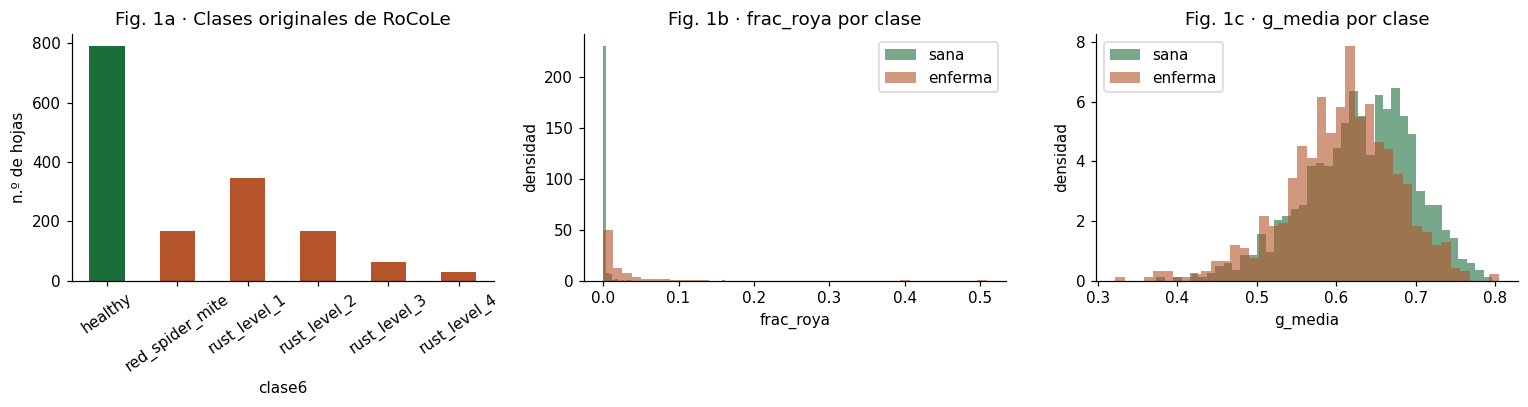

In [5]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda 4 · EDA: faltantes, balance, escalas, grupos y separabilidad
# Qué hace · Resume la tabla y dibuja la distribución de clases y de los rasgos por clase.
# Por qué  · Las decisiones de partición y preprocesamiento (tabla de abajo) salen de aquí.
falt = tabla[RASGOS].isna().sum()
print("(a) Faltantes en rasgos:", int(falt.sum()), "celdas", "(ninguno)" if falt.sum() == 0 else falt[falt > 0].to_dict())
print(f"(b) Enfermas: {tabla['y'].mean()*100:.1f} % | severidad (de las enfermas):")
print(tabla.loc[tabla.y == 1, "clase6"].value_counts(normalize=True).mul(100).round(1).to_string())
esc = tabla[RASGOS].agg(["min", "max", "std"]).T
esc["rango"] = esc["max"] - esc["min"]
print("\n(c) Escalas de los rasgos (desviación estándar máx./mín. entre rasgos: "
      f"{esc['std'].max()/max(esc['std'].min(), 1e-12):.0f}×):"); print(esc.round(4).to_string())
hojas_planta = tabla.groupby("planta")["y"].agg(["size", "mean"])
print(f"\n(d) Hojas por planta: {hojas_planta['size'].min()}–{hojas_planta['size'].max()} | "
      f"plantas con hojas sanas y enfermas a la vez: {((hojas_planta['mean'] > 0) & (hojas_planta['mean'] < 1)).sum()} de {len(hojas_planta)}")
auc_rasgo = {r: roc_auc_score(tabla["y"], tabla[r].fillna(tabla[r].median())) for r in RASGOS}
auc_rasgo = pd.Series(auc_rasgo).apply(lambda a: max(a, 1 - a)).sort_values(ascending=False)
print("\n(e) AUC de cada rasgo usado solo (0,5 = azar):"); print(auc_rasgo.round(3).to_string())

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
tabla["clase6"].value_counts().reindex(["healthy", "red_spider_mite", "rust_level_1", "rust_level_2",
                                         "rust_level_3", "rust_level_4"]).plot.bar(
    ax=ax[0], color=[COLOR_SANA] + [COLOR_ENF] * 5)
ax[0].set_title("Fig. 1a · Clases originales de RoCoLe"); ax[0].set_ylabel("n.º de hojas"); ax[0].tick_params(axis="x", rotation=35)
for i, r in enumerate(auc_rasgo.index[:2]):
    for cl, col, nom in [(0, COLOR_SANA, "sana"), (1, COLOR_ENF, "enferma")]:
        ax[i + 1].hist(tabla.loc[tabla.y == cl, r], bins=40, alpha=0.6, color=col, label=nom, density=True)
    ax[i + 1].set_title(f"Fig. 1{'bc'[i]} · {r} por clase"); ax[i + 1].set_xlabel(r); ax[i + 1].set_ylabel("densidad"); ax[i + 1].legend()
plt.tight_layout(); plt.show()

### Decisiones que deja el EDA

| # | Hallazgo | Decisión |
|---|---|---|
| a | El CSV crudo trae columnas vacías (benchmark, acuerdo) y un dato personal (correo del anotador); un nombre de archivo es irregular (`C11P11HE.jpg`). | Se descartan esas columnas antes de mostrar nada; la planta se extrae con una expresión que tolera el nombre irregular. Si algún polígono no produce máscara, esa foto se **descarta** (no se imputa una hoja inventada). |
| b | La etiqueta binaria está casi balanceada (≈ 49 % enfermas), pero la severidad no: la roya 3 y 4 son pocas. | Partición **estratificada de hecho** (ver la proporción por conjunto) y análisis de errores **por severidad** en la sección 10. Sin `pos_weight`: el balance no lo exige. |
| c | Los rasgos viven en escalas muy distintas (fracciones de píxel frente a medias de color). | **Estandarizar** con un `StandardScaler` ajustado **solo con el entrenamiento**, después de partir. |
| d | Cada planta aporta ≈ 4 hojas, fotografiadas en la misma sesión y con la misma luz; casi todas tienen hojas sanas y enfermas. | Partir **por planta** (`GroupShuffleSplit`): una planta entera cae en un solo conjunto, para que la prueba mida hojas de plantas nunca vistas y no «recuerde» la iluminación. |
| e | Ningún rasgo solo separa bien las clases (ver AUC por rasgo): la señal está repartida. | Justifica un modelo **no lineal** que combine rasgos (MLP) frente a un umbral sobre un solo número (la línea base del escalar crudo, sección 6). |

## 5. Partición por planta (60 / 20 / 20) y escalado sin fuga

In [6]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda 5 · Partición por planta y escalado sin fuga
# Qué hace · Divide por planta en entrenamiento / validación / prueba y ajusta el escalador SOLO con el entrenamiento.
# Por qué  · Hojas de la misma planta comparten luz y cámara: mezclarlas entre conjuntos inflaría la prueba.
tabla = tabla.dropna(subset=RASGOS).reset_index(drop=True)
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEMILLA)   # E-4: partición por planta
idx_resto, idx_test = next(gss.split(tabla, tabla["y"], tabla["planta"]))
resto = tabla.iloc[idx_resto]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEMILLA)   # 0,25 × 0,80 = 0,20
i_tr, i_va = next(gss2.split(resto, resto["y"], resto["planta"]))
train, val, test = resto.iloc[i_tr], resto.iloc[i_va], tabla.iloc[idx_test]
assert not (set(train.planta) & set(val.planta)) and not (set(train.planta) & set(test.planta)) \
       and not (set(val.planta) & set(test.planta)), "Una planta aparece en dos conjuntos"

escalador = StandardScaler().fit(train[RASGOS])          # ← solo entrenamiento
X_train, X_val, X_test = (escalador.transform(d[RASGOS]).astype(np.float32) for d in (train, val, test))
y_train, y_val, y_test = (d["y"].to_numpy() for d in (train, val, test))
resumen_part = pd.DataFrame({"conjunto": ["entrenamiento", "validación", "prueba"],
                             "hojas": [len(train), len(val), len(test)],
                             "plantas": [train.planta.nunique(), val.planta.nunique(), test.planta.nunique()],
                             "% enfermas": [round(d.y.mean() * 100, 1) for d in (train, val, test)]})
resumen_part

,conjunto,hojas,plantas,% enfermas
0,entrenamiento,936,234,50.1
1,validación,312,78,49.0
2,prueba,312,78,47.1


## 6. Línea base comprometida (en el conjunto de prueba)

Dos referencias que el MLP debe superar, como se comprometió en la Propuesta:

1. **Clase mayoritaria** del entrenamiento: predice siempre lo mismo. Su *recall* de «enferma» vale 0 si la mayoritaria es «sana».
2. **Escalar crudo**: el rasgo `frac_roya` (proporción de píxeles color roya) usado solo, con el umbral elegido en **validación** (el que maximiza F1) y aplicado una vez a prueba. Responde a la pregunta del cliente «¿no basta con medir cuánto naranja tiene la hoja?».

In [7]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda 6 · Líneas base: clase mayoritaria y escalar crudo (frac_roya)
# Qué hace · Calcula exactitud, precisión, recall y F1 de la clase de riesgo para las dos referencias.
# Por qué  · Toda métrica del MLP se lee frente a estas cifras; son el punto de comparación de la Fase 2.
def metricas(y, yhat, prob=None):
    p, r, f, _ = precision_recall_fscore_support(y, yhat, labels=[1], zero_division=0)
    out = {"exactitud": accuracy_score(y, yhat), "precision_enf": p[0], "recall_enf": r[0], "f1_enf": f[0]}
    if prob is not None:
        out["auc"] = roc_auc_score(y, prob)
    return out

mayoritaria = int(pd.Series(y_train).mode()[0])
base_mayor = metricas(y_test, np.full_like(y_test, mayoritaria))

ESCALAR = "frac_roya"
signo = 1 if train.loc[train.y == 1, ESCALAR].mean() > train.loc[train.y == 0, ESCALAR].mean() else -1
cands = np.quantile(val[ESCALAR], np.linspace(0.02, 0.98, 97))
f1s = [metricas(y_val, (signo * val[ESCALAR] > signo * c).astype(int))["f1_enf"] for c in cands]
umbral_escalar = float(cands[int(np.argmax(f1s))])
base_escalar = metricas(y_test, (signo * test[ESCALAR] > signo * umbral_escalar).astype(int), signo * test[ESCALAR])

# Mismo escalar con el criterio del cliente (recall ≥ 0,90 en validación), para comparar con el MLP en igualdad
cands_r = [c for c in cands if ((signo * val[ESCALAR] > signo * c)[val.y == 1]).mean() >= 0.90]
umbral_escalar_r = float(max(cands_r)) if signo == 1 else float(min(cands_r))
base_escalar_r = metricas(y_test, (signo * test[ESCALAR] > signo * umbral_escalar_r).astype(int), signo * test[ESCALAR])

lineas_base = pd.DataFrame({f"Clase mayoritaria ({'enferma' if mayoritaria else 'sana'})": base_mayor,
                            f"Escalar crudo: {ESCALAR} > {umbral_escalar:.4f} (máx. F1 en val.)": base_escalar,
                            f"Escalar crudo: {ESCALAR} > {umbral_escalar_r:.4f} (recall ≥ 0,90 en val.)": base_escalar_r}).T.round(3)
lineas_base

,exactitud,precision_enf,recall_enf,f1_enf,auc
Clase mayoritaria (enferma),0.471,0.471,1.000,0.641,NaN
Escalar crudo: frac_roya > 0.0008 (máx. F1 en val.),0.843,0.814,0.864,0.838,0.897
"Escalar crudo: frac_roya > 0.0005 (recall ≥ 0,90 en val.)",0.840,0.790,0.898,0.841,0.897


## 7. Arquitectura del MLP: 14 → 16 → 8 → 1 (salida en *logit*)

- **Dos capas ocultas con ReLU.** El EDA mostró que ningún rasgo separa solo (AUC por rasgo moderado): lo que delata la roya es una **combinación** —poco verde *y* más naranja *y* textura rota—, y esa combinación no es una frontera lineal. Sin la no linealidad φ, apilar capas colapsa en una sola transformación lineal (W₂(W₁x) = Wx) y el MLP sería una regresión logística. ReLU, max(0, z), aporta esa no linealidad con un gradiente que no se apaga para z > 0 (a diferencia de la sigmoide en capas ocultas, que satura en los extremos).
- **Salida en *logit*** (`nn.Linear(8, 1)` sin activación). La sigmoide vive dentro de `BCEWithLogitsLoss` durante el entrenamiento y se aplica con `torch.sigmoid` solo en la evaluación: así se evita la **doble sigmoide**.
- **Dropout** configurable (0 por defecto); se usa en las secciones 9 y 9b.
- **Capacidad:** 16 → 8 es la referencia de la ficha (385 parámetros para 14 rasgos y 936 hojas de entrenamiento). Se compara con una red 64 → 32 (3.073 parámetros) en las secciones 8 y 9b para justificarla con una medición.

In [8]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda 7 · Clase del MLP (dos capas ocultas, salida en logit)
# Qué hace · Define el modelo con tamaños configurables y Dropout opcional.
# Por qué  · Dos capas ocultas ReLU (exigido) y salida lineal compatible con BCEWithLogitsLoss.
class MLP(nn.Module):
    def __init__(self, n_feat, h1=16, h2=8, p_dropout=0.0):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(n_feat, h1), nn.ReLU(), nn.Dropout(p_dropout),   # capa oculta 1
            nn.Linear(h1, h2), nn.ReLU(), nn.Dropout(p_dropout),       # capa oculta 2
            nn.Linear(h2, 1))                                          # salida: LOGIT (sin sigmoide)

    def forward(self, x):
        return self.red(x)                     # la sigmoide vive en la pérdida y en la evaluación

def n_parametros(m):
    return sum(p.numel() for p in m.parameters())

print(MLP(len(RASGOS)))
print("Parámetros 16→8:", n_parametros(MLP(len(RASGOS))), "| 64→32:", n_parametros(MLP(len(RASGOS), 64, 32)))

MLP(
  (red): Sequential(
    (0): Linear(in_features=14, out_features=16, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=16, out_features=8, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=8, out_features=1, bias=True)
  )
)
Parámetros 16→8: 385 | 64→32: 3073


## 8. Pérdida, optimizador y bucle de entrenamiento explícito

- **Pérdida:** `nn.BCEWithLogitsLoss()`, la entropía cruzada binaria sobre el *logit* (forma estable: ℓ = max(z, 0) − y·z + log(1 + e^{−|z|})). La etiqueta va como flotante de forma `(N, 1)`, igual que el *logit*.
- **Optimizador:** Adam con tasa 10⁻². Con **lote completo** cada época es una sola actualización, y con la tasa por defecto de Adam (10⁻³) 50 épocas no alcanzan a converger.
- **Bucle**, en el orden del Módulo 1: **1 · forward → 2 · pérdida → 3 · zero_grad → 4 · backward → 5 · step**; luego la pérdida de validación con `model.eval()` y `torch.no_grad()`.
- **Parada temprana:** se guarda el estado de la época con la menor pérdida de validación y se **restaura** al final (con paciencia opcional). Cada 10 épocas se escribe un **punto de control** en Drive.

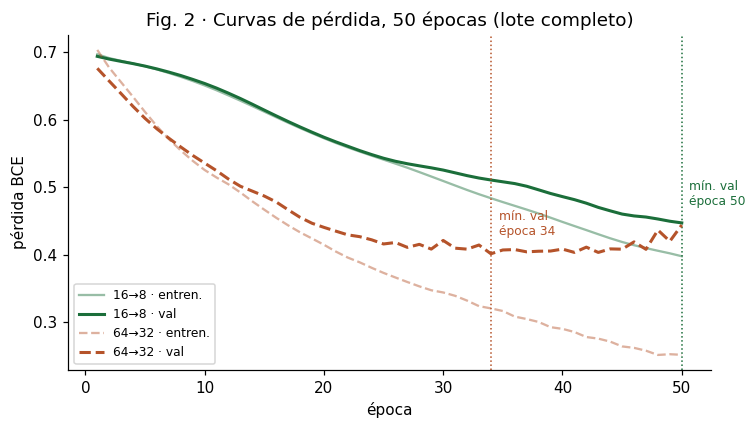

,capas,mejor_epoca,val_min,train_en_mejor,brecha_en_mejor,val_final,brecha_final
nombre,,,,,,,
base_16x8,16→8,50,0.4469,0.3930,0.0539,0.4469,0.0494
cap_64x32,64→32,34,0.4011,0.3163,0.0849,0.4438,0.1925


In [9]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda 8 · Bucle de entrenamiento explícito con parada temprana y punto de control
# Qué hace · Entrena un MLP con lote completo, registra las pérdidas y restaura la mejor época de validación.
# Por qué  · Es el corazón de la fase (C2) y produce las curvas que diagnostican el sobreajuste (C3).
def a_tensor(X, y):
    return torch.tensor(np.array(X), dtype=torch.float32), torch.tensor(np.array(y)).float().view(-1, 1)

Xtr_t, ytr_t = a_tensor(X_train, y_train)
Xva_t, yva_t = a_tensor(X_val, y_val)
Xte_t, yte_t = a_tensor(X_test, y_test)

def entrenar(Xtr, ytr, Xva, yva, h1=16, h2=8, p_dropout=0.0, lr=1e-2, epocas=50, paciencia=None,
             nombre="corrida", semilla=SEMILLA):
    torch.manual_seed(semilla)
    modelo = MLP(Xtr.shape[1], h1, h2, p_dropout)
    criterio = nn.BCEWithLogitsLoss()                      # sigmoide + BCE en un paso estable
    optim = torch.optim.Adam(modelo.parameters(), lr=lr)
    hist = {"train": [], "val": []}
    mejor_val, mejor_epoca, mejor_estado, sin_mejora = float("inf"), 0, None, 0
    ruta_ckpt = os.path.join(BASE, f"ckpt_{nombre}.pt")
    for epoca in range(1, epocas + 1):
        modelo.train()                                     # Dropout activo
        logits = modelo(Xtr)                               # 1 · forward (logits)
        perdida = criterio(logits, ytr)                    # 2 · pérdida
        optim.zero_grad()                                  # 3 · limpia gradientes previos
        perdida.backward()                                 # 4 · retropropagación
        optim.step()                                       # 5 · actualiza pesos
        modelo.eval()                                      # Dropout apagado para medir validación
        with torch.no_grad():
            perdida_val = criterio(modelo(Xva), yva).item()
        hist["train"].append(perdida.item()); hist["val"].append(perdida_val)
        if perdida_val < mejor_val:                        # parada temprana: guarda el mejor estado
            mejor_val, mejor_epoca, sin_mejora = perdida_val, epoca, 0
            mejor_estado = copy.deepcopy(modelo.state_dict())
        else:
            sin_mejora += 1
        if epoca % 10 == 0:                                # punto de control para reanudar
            torch.save({"epoca": epoca, "modelo": modelo.state_dict(), "optim": optim.state_dict(),
                        "mejor_epoca": mejor_epoca, "mejor_estado": mejor_estado}, ruta_ckpt)
        if paciencia is not None and sin_mejora >= paciencia:
            break
    ultimo = {"train": hist["train"][-1], "val": hist["val"][-1]}
    modelo.load_state_dict(mejor_estado)                   # versión final = mínimo de validación
    with torch.no_grad():
        modelo.eval(); perdida_tr_mejor = criterio(modelo(Xtr), ytr).item()
    res = {"nombre": nombre, "capas": f"{h1}→{h2}", "dropout": p_dropout, "lr": lr, "epocas_corridas": len(hist["train"]),
           "n_entrenamiento": len(ytr), "mejor_epoca": mejor_epoca, "val_min": mejor_val,
           "train_en_mejor": perdida_tr_mejor, "brecha_en_mejor": mejor_val - perdida_tr_mejor,
           "val_final": ultimo["val"], "train_final": ultimo["train"], "brecha_final": ultimo["val"] - ultimo["train"]}
    return modelo, hist, res

def plot_curvas(historias, titulo, marcar=True, ax=None):
    ax = ax or plt.subplots(figsize=(7, 4))[1]
    estilos = [("-", COLOR_SANA), ("--", COLOR_ENF), (":", "#3b4cc0"), ("-.", COLOR_GRIS)]
    for (etq, h), (ls, col) in zip(historias.items(), estilos):
        ep = np.arange(1, len(h["train"]) + 1)
        ax.plot(ep, h["train"], ls, color=col, alpha=0.45, label=f"{etq} · entren.")
        ax.plot(ep, h["val"], ls, color=col, lw=2, label=f"{etq} · val")
        if marcar:
            e = int(np.argmin(h["val"])) + 1
            ax.axvline(e, color=col, ls=":", lw=1); ax.annotate(f"mín. val\népoca {e}", (e, min(h["val"])),
                                                                 textcoords="offset points", xytext=(5, 12), fontsize=8, color=col)
    ax.set_xlabel("época"); ax.set_ylabel("pérdida BCE"); ax.set_title(titulo); ax.legend(fontsize=8)
    return ax

# Corrida base (referencia de la ficha) y comparación de capacidad, 50 épocas cada una
modelo_base, hist_base, res_base = entrenar(Xtr_t, ytr_t, Xva_t, yva_t, 16, 8, nombre="base_16x8")
_, hist_grande, res_grande = entrenar(Xtr_t, ytr_t, Xva_t, yva_t, 64, 32, nombre="cap_64x32")
plot_curvas({"16→8": hist_base, "64→32": hist_grande}, "Fig. 2 · Curvas de pérdida, 50 épocas (lote completo)")
plt.tight_layout(); plt.show()
comparacion_capacidad = pd.DataFrame([res_base, res_grande]).set_index("nombre")[
    ["capas", "mejor_epoca", "val_min", "train_en_mejor", "brecha_en_mejor", "val_final", "brecha_final"]].round(4)
comparacion_capacidad

**Lectura de las curvas (Fig. 2).** Las dos redes reducen la pérdida de entrenamiento, así que el bucle funciona. Pero cuentan historias distintas:

- **16 → 8:** su mínimo de validación cae justo en la **época 50**, la última (0,4469). La curva todavía baja: con 50 actualizaciones de lote completo la red **no terminó de aprender** (subajuste).
- **64 → 32:** llega antes a su mínimo (**época 34**, 0,4011) y después la validación **sube** (0,4438 en la época 50) mientras la de entrenamiento sigue bajando: la brecha pasa de 0,085 a 0,193. Ocho veces más parámetros (3.073 frente a 385) le permiten empezar a memorizar.

Conclusión: 50 épocas no bastan para decidir. La sección 9b repite la comparación con más épocas y parada temprana.

## 9. Desafío: inducir el sobreajuste y corregirlo con *Dropout*

Con ≈ 900 hojas y 50 actualizaciones la red pequeña no tiene tiempo de memorizar. Para **provocar** el sobreajuste se combinan las tres palancas clásicas:

- **pocos datos:** 150 hojas de entrenamiento (de plantas del conjunto de entrenamiento);
- **mucha capacidad:** red 128 → 64;
- **muchas épocas:** 600 actualizaciones.

Luego se corrige con la **misma red, los mismos datos y las mismas épocas**, cambiando dos palancas: **Dropout 0,5** y **tasa 10⁻³**, más la parada temprana que conserva el mínimo de validación. La validación es la misma de siempre (plantas que el modelo no vio).

Subconjunto pequeño: 152 hojas de 38 plantas


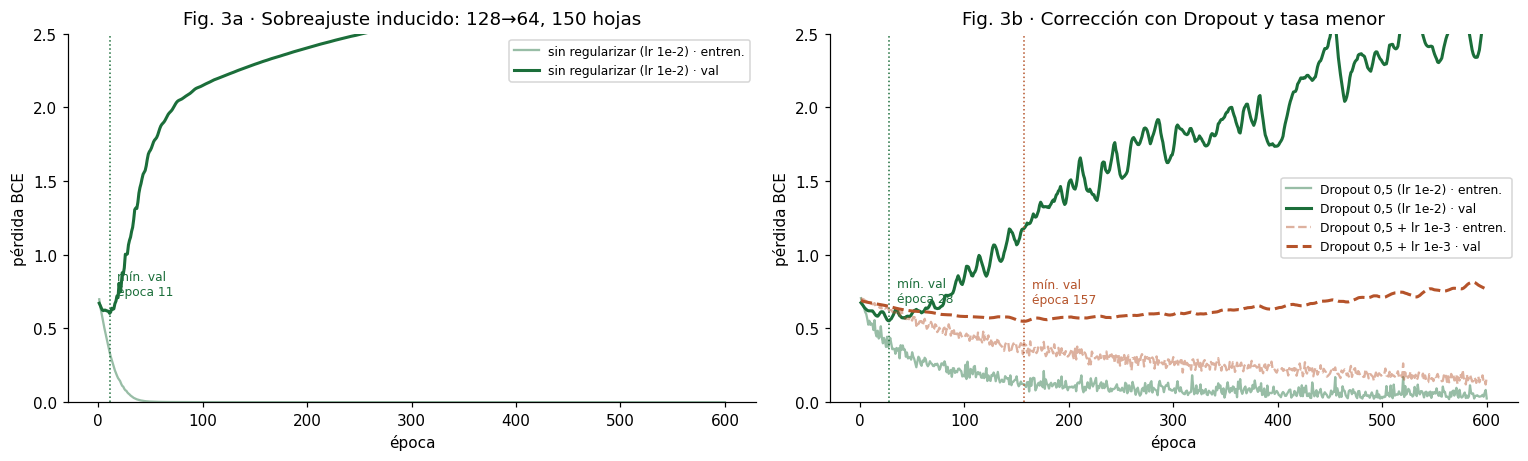

,capas,dropout,lr,mejor_epoca,val_min,train_en_mejor,brecha_en_mejor,val_final,train_final,brecha_final
nombre,,,,,,,,,,
sobreajuste,128→64,0.0,0.010,11,0.6025,0.3103,0.2922,2.8898,0.0000,2.8898
dropout05,128→64,0.5,0.010,28,0.5521,0.3182,0.2339,2.7865,0.0252,2.7614
dropout05_lr1e-3,128→64,0.5,0.001,157,0.5491,0.3033,0.2458,0.7660,0.1716,0.5943


In [10]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda 9 · Sobreajuste inducido (red grande + pocos datos + 600 épocas) y su corrección
# Qué hace · Entrena tres corridas comparables sobre las mismas 150 hojas y compara sus curvas.
# Por qué  · Criterio 3: mostrar el sobreajuste, nombrar la época del mínimo y cuantificar el efecto del remedio.
rng = np.random.default_rng(SEMILLA)
plantas_peq = rng.choice(train.planta.unique(), size=38, replace=False)        # ≈ 150 hojas
m_peq = train.planta.isin(plantas_peq).to_numpy()
Xp_t, yp_t = a_tensor(X_train[m_peq], y_train[m_peq])
print(f"Subconjunto pequeño: {m_peq.sum()} hojas de {len(plantas_peq)} plantas")

_, h_sobre, r_sobre = entrenar(Xp_t, yp_t, Xva_t, yva_t, 128, 64, 0.0, 1e-2, 600, nombre="sobreajuste")
_, h_drop, r_drop = entrenar(Xp_t, yp_t, Xva_t, yva_t, 128, 64, 0.5, 1e-2, 600, nombre="dropout05")
_, h_reg, r_reg = entrenar(Xp_t, yp_t, Xva_t, yva_t, 128, 64, 0.5, 1e-3, 600, nombre="dropout05_lr1e-3")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
plot_curvas({"sin regularizar (lr 1e-2)": h_sobre}, "Fig. 3a · Sobreajuste inducido: 128→64, 150 hojas", ax=ax[0])
plot_curvas({"Dropout 0,5 (lr 1e-2)": h_drop, "Dropout 0,5 + lr 1e-3": h_reg},
            "Fig. 3b · Corrección con Dropout y tasa menor", ax=ax[1])
lim = max(max(h_sobre["val"][:400]), 1.0); [a.set_ylim(0, min(lim, 2.5)) for a in ax]
plt.tight_layout(); plt.show()

tabla_reg = pd.DataFrame([r_sobre, r_drop, r_reg]).set_index("nombre")[
    ["capas", "dropout", "lr", "mejor_epoca", "val_min", "train_en_mejor", "brecha_en_mejor",
     "val_final", "train_final", "brecha_final"]].round(4)
tabla_reg

**Lectura del experimento (Fig. 3).** El sobreajuste aparece de libro:

| Corrida (128 → 64, 152 hojas, 600 épocas) | Época del mín. de validación | Pérdida mín. de validación | Pérdida final de validación | Brecha final (val − entren.) |
|---|---|---|---|---|
| Sin regularizar, tasa 10⁻² | **11** | 0,603 | 2,89 | 2,89 |
| Dropout 0,5, tasa 10⁻² | **28** | 0,552 | 2,79 | 2,76 |
| Dropout 0,5 + tasa 10⁻³ | **157** | 0,549 | 0,77 | 0,59 |

- **Sin regularizar**, la pérdida de entrenamiento llega a 0,0000 —la red se aprendió de memoria las 152 hojas— mientras la de validación toca su mínimo en la época 11 y luego se multiplica por casi cinco.
- **El Dropout solo** baja el mínimo (0,603 → 0,552) y lo retrasa (época 11 → 28), pero con tasa 10⁻² la red memoriza igual, solo que más despacio.
- **Dropout más tasa 10⁻³** retrasa el mínimo hasta la época 157 y deja la brecha final en 0,59: **cinco veces menor**. Aun así la validación termina subiendo; por eso el modelo que se conserva es siempre el de la **parada temprana** (el mínimo de validación), nunca el de la última época.

*(Las corridas con Dropout dependen del generador aleatorio de PyTorch; sus cifras pueden variar entre versiones. Las que valen son las de la tabla impresa por el cuaderno, que son las de esta ejecución.)*

## 9b. Selección del modelo final: lo aprendido, aplicado al conjunto completo

Las secciones 8 y 9 dejan dos lecciones: (1) con 50 épocas la red 16 → 8 **no termina de aprender** (su validación aún baja en la última época); (2) el *Dropout* con parada temprana **frena la memorización**. Se aplican ambas al conjunto completo de entrenamiento: hasta **600 épocas** con **paciencia de 60** (se detiene si la validación no mejora en 60 épocas) y se restaura siempre la mejor época.

Se comparan cinco configuraciones con el **mismo** criterio: la **pérdida mínima de validación**. La prueba no interviene en la elección.

Modelo final (menor pérdida de validación): 16→8 Dropout 0,3


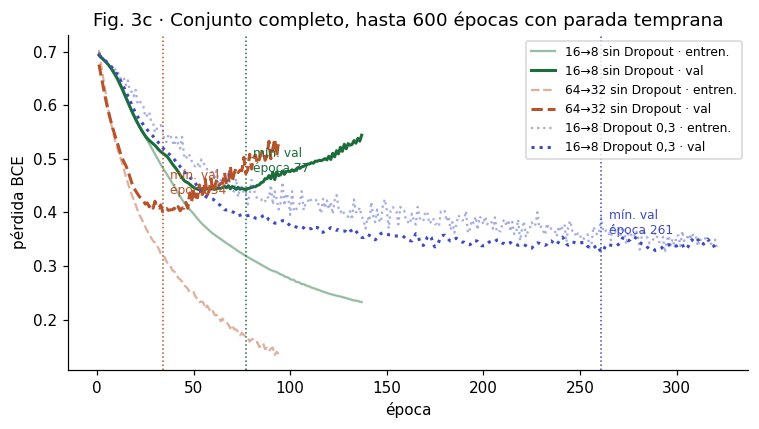

,capas,dropout,mejor_epoca,epocas_corridas,val_min,train_en_mejor,brecha_en_mejor
config,,,,,,,
16→8 sin Dropout,16→8,0.0,77,137,0.4421,0.3168,0.1253
64→32 sin Dropout,64→32,0.0,34,94,0.4011,0.3163,0.0849
"16→8 Dropout 0,1",16→8,0.1,261,321,0.3345,0.2551,0.0794
"16→8 Dropout 0,2",16→8,0.2,238,298,0.3347,0.2782,0.0565
"16→8 Dropout 0,3",16→8,0.3,261,321,0.3262,0.2966,0.0297


In [11]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda 9b · Selección del modelo final por pérdida mínima de validación (la prueba no se mira)
# Qué hace · Entrena 5 configuraciones con parada temprana y elige la de menor pérdida de validación.
# Por qué  · Criterio 3 (Estratégico): comparar intervenciones en una tabla y elegir con argumento medido.
EPOCAS_SEL, PACIENCIA_SEL = 600, 60
CONFIGS = [("16→8 sin Dropout", 16, 8, 0.0), ("64→32 sin Dropout", 64, 32, 0.0),
           ("16→8 Dropout 0,1", 16, 8, 0.1), ("16→8 Dropout 0,2", 16, 8, 0.2), ("16→8 Dropout 0,3", 16, 8, 0.3)]
resultados_sel, historias_sel, modelos_sel = [], {}, {}
for etq, h1, h2, p in CONFIGS:
    m, h, r = entrenar(Xtr_t, ytr_t, Xva_t, yva_t, h1, h2, p, 1e-2, EPOCAS_SEL, PACIENCIA_SEL, nombre=f"sel_{h1}x{h2}_p{p}")
    r["config"] = etq; resultados_sel.append(r); historias_sel[etq] = h; modelos_sel[etq] = m
seleccion = pd.DataFrame(resultados_sel).set_index("config")[
    ["capas", "dropout", "mejor_epoca", "epocas_corridas", "val_min", "train_en_mejor", "brecha_en_mejor"]].round(4)
CONFIG_FINAL = seleccion["val_min"].idxmin()
H1_F, H2_F, P_F = [(h1, h2, p) for e, h1, h2, p in CONFIGS if e == CONFIG_FINAL][0]
modelo_final = modelos_sel[CONFIG_FINAL]
print(f"Modelo final (menor pérdida de validación): {CONFIG_FINAL}")

plot_curvas({k: historias_sel[k] for k in ["16→8 sin Dropout", "64→32 sin Dropout", CONFIG_FINAL]},
            "Fig. 3c · Conjunto completo, hasta 600 épocas con parada temprana")
plt.tight_layout(); plt.show()
seleccion

**Lectura de la selección (Fig. 3c y tabla).** Con tiempo suficiente, la 16 → 8 sin Dropout mejora poco (mínimo 0,442 en la época 77) y empieza a memorizar. La red grande, 64 → 32, baja más (0,401), pero lo hace con ocho veces más parámetros y se detiene en la época 34. Las tres variantes de **16 → 8 con Dropout** son claramente mejores, con mínimos de validación entre 0,326 y 0,335 en las épocas 238–261. La elegida, **Dropout 0,3** (mínimo 0,3262 en la época 261), tiene además la **brecha más pequeña** entre entrenamiento y validación (0,030). Conclusión medida: aquí rinde más **regularizar una red pequeña** que agrandarla. El modelo final es el de la fila marcada en la celda anterior, restaurado en su mínimo de validación.

## 10. Umbral elegido en validación, evaluación única en prueba y análisis de errores

**El umbral es una decisión del cliente, no un detalle técnico.** Para el técnico de la finca, una **alarma omitida** (falso negativo) deja que la roya esporule y se extienda a las plantas vecinas, con pérdida de cosecha; una **falsa alarma** (falso positivo) cuesta una visita de inspección y, si se fumiga sin revisar, fungicida innecesario. Por eso se fija como requisito un ***recall* de «enferma» de al menos 0,90 en validación** y, entre los umbrales que lo cumplen, se toma el **más alto** (el que menos falsas alarmas genera). La prueba se mide **una sola vez** con ese umbral.

In [12]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda 10a · Elección del umbral en VALIDACIÓN (nunca en prueba)
# Qué hace · Barre umbrales sobre las probabilidades de validación y elige el más alto con recall ≥ 0,90.
# Por qué  · Criterio 4 (Estratégico): umbral ligado al costo de cada error y elegido fuera de la prueba.
RECALL_OBJETIVO = 0.90
modelo_final.eval()                                                  # modelo elegido en la celda 9b
with torch.no_grad():
    prob_val = torch.sigmoid(modelo_final(Xva_t)).numpy().ravel()     # sigmoide solo en evaluación
barrido = []
for u in np.round(np.arange(0.05, 0.951, 0.01), 2):
    mt = metricas(y_val, (prob_val >= u).astype(int))
    barrido.append({"umbral": u, **mt})
barrido = pd.DataFrame(barrido)
cumplen = barrido[barrido.recall_enf >= RECALL_OBJETIVO]
UMBRAL = float(cumplen.umbral.max()) if len(cumplen) else 0.5
print(f"Umbral elegido en validación: {UMBRAL:.2f}")
barrido[barrido.umbral.isin([0.3, 0.4, 0.5, UMBRAL])].round(3)

Umbral elegido en validación: 0.33


,umbral,exactitud,precision_enf,recall_enf,f1_enf
25,0.30,0.843,0.786,0.935,0.854
28,0.33,0.846,0.793,0.928,0.855
35,0.40,0.856,0.842,0.869,0.855
45,0.50,0.862,0.877,0.837,0.856


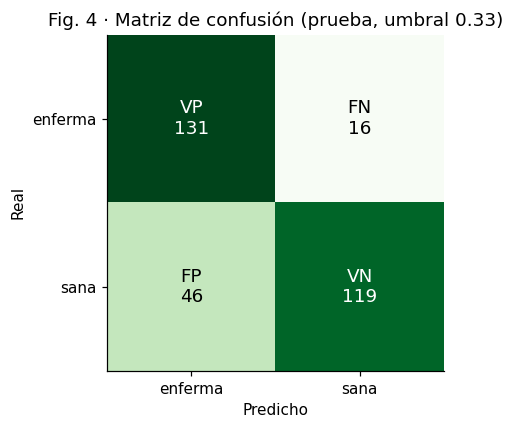

                  precisión  recall     F1  soporte
enferma (riesgo)      0.740   0.891  0.809      147
sana                  0.881   0.721  0.793      165

VP=131 FN=16 FP=46 VN=119


,exactitud,precision_enf,recall_enf,f1_enf,auc
Clase mayoritaria (enferma),0.471,0.471,1.000,0.641,NaN
Escalar crudo: frac_roya > 0.0008 (máx. F1 en val.),0.843,0.814,0.864,0.838,0.897
"Escalar crudo: frac_roya > 0.0005 (recall ≥ 0,90 en val.)",0.840,0.790,0.898,0.841,0.897
"MLP 16→8 Dropout 0,3 · umbral 0,50",0.843,0.831,0.837,0.834,0.910
"MLP 16→8 Dropout 0,3 · umbral 0.33 (recall ≥ 0,90 en val.)",0.801,0.740,0.891,0.809,0.910


In [13]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda 10b · Evaluación en PRUEBA, una sola vez: matriz de confusión y métricas por clase
# Qué hace · Aplica el umbral de validación al conjunto de prueba y compara con las líneas base.
# Por qué  · Criterio 4: matriz, precisión/recall/F1 por clase, frente a la clase mayoritaria y al escalar crudo.
with torch.no_grad():
    prob_test = torch.sigmoid(modelo_final(Xte_t)).numpy().ravel()
pred_test = (prob_test >= UMBRAL).astype(int)
pred_05 = (prob_test >= 0.5).astype(int)
cm = confusion_matrix(y_test, pred_test, labels=[1, 0])        # positiva (enferma) primero
VP, FN, FP, VN = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]

fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap="Greens")
NOMBRES_CELDA = [["VP", "FN"], ["FP", "VN"]]
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{NOMBRES_CELDA[i][j]}\n{v}",
            ha="center", va="center", fontsize=12, color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["enferma", "sana"]); ax.set_yticks([0, 1], ["enferma", "sana"])
ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.set_title(f"Fig. 4 · Matriz de confusión (prueba, umbral {UMBRAL:.2f})")
plt.tight_layout(); plt.show()

p, r, f, s = precision_recall_fscore_support(y_test, pred_test, labels=[1, 0], zero_division=0)
por_clase = pd.DataFrame({"precisión": p, "recall": r, "F1": f, "soporte": s}, index=["enferma (riesgo)", "sana"]).round(3)
print(por_clase.to_string())
mlp_umbral = metricas(y_test, pred_test, prob_test)
mlp_05 = metricas(y_test, pred_05, prob_test)
comparacion_final = pd.concat([lineas_base,
                               pd.DataFrame({f"MLP {CONFIG_FINAL} · umbral 0,50": mlp_05,
                                             f"MLP {CONFIG_FINAL} · umbral {UMBRAL:.2f} (recall ≥ 0,90 en val.)": mlp_umbral}).T.round(3)])
print(f"\nVP={VP} FN={FN} FP={FP} VN={VN}")
comparacion_final

In [14]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda 10c · Análisis de errores: ¿qué hojas enfermas se escapan?
# Qué hace · Calcula la tasa de falsos negativos por severidad (subgrupo) y describe los falsos positivos.
# Por qué  · No hay territorios ni personas (son hojas de un solo lote), pero sí subgrupos de severidad:
#            el costo de un FN depende de en qué etapa de la enfermedad se escapa.
err = test.assign(prob=prob_test, pred=pred_test)
enf = err[err.y == 1].assign(                                     # E-6
    fn=lambda d: (d.pred == 0).astype(int))
por_sev = enf.groupby("clase6").agg(hojas=("y", "size"), detectadas=("pred", "sum"), FN=("fn", "sum"), tasa_FN=("fn", "mean")).round(3)
print("Falsos negativos por severidad (prueba): ver tabla")
fp = err[(err.y == 0) & (err.pred == 1)]
print(f"\nFalsos positivos: {len(fp)} hojas sanas marcadas como enfermas. "
      f"frac_roya media en FP = {fp.frac_roya.mean():.4f} frente a {err[(err.y==0)&(err.pred==0)].frac_roya.mean():.4f} en las sanas bien clasificadas.")
por_sev

Falsos negativos por severidad (prueba): ver tabla

Falsos positivos: 46 hojas sanas marcadas como enfermas. frac_roya media en FP = 0.0030 frente a 0.0002 en las sanas bien clasificadas.


,hojas,detectadas,FN,tasa_FN
clase6,,,,
red_spider_mite,28,27,1,0.036
rust_level_1,68,54,14,0.206
rust_level_2,28,27,1,0.036
rust_level_3,15,15,0,0.000
rust_level_4,8,8,0,0.000


### Lectura técnica y ética de los errores

**Qué tan bien funciona.** En las 312 hojas de prueba (78 plantas nunca vistas), con el umbral elegido en validación (0,33), el MLP avisa **131 de las 147 hojas enfermas** (*recall* 0,891) y, de cada 100 alertas, **74 son ciertas** (precisión 0,740): 16 alarmas omitidas y 46 falsas alarmas. Frente a las líneas base:

- Decir «enferma» siempre da exactitud 0,471: el MLP la supera con holgura (0,801).
- La regla de un solo número, `frac_roya` (cuánto naranja tiene la hoja), con el **mismo** criterio de *recall* ≥ 0,90 en validación, logra en prueba *recall* 0,898 y precisión 0,790 (F1 0,841): **iguala la detección del MLP con unas 11 falsas alarmas menos**. El MLP solo la supera en ordenar los casos (AUC 0,910 frente a 0,897).

Lectura honesta: en esta versión tabular, casi toda la señal útil está en el color naranja, y combinar 14 rasgos no mejora la decisión del cliente. Ese techo es justo lo que la Fase 2 debe romper con una CNN sobre la foto completa.

**Dónde falla.** Los escapes se concentran en la **roya de nivel 1**: 14 de 68 hojas (21 %) no se detectan, la etapa temprana, con pocas manchas pequeñas. Las roya 3 y 4 se detectan todas. Es el peor lugar para fallar, porque el valor de una alerta *temprana* está en ese nivel. Las falsas alarmas tienen, en promedio, más píxeles naranja que las hojas sanas bien clasificadas: hojas sanas con brillos amarillos o tejido envejecido.

*Marco ético para la inteligencia artificial en Colombia* (Guío Español et al., 2021):

- **Transparencia y explicación.** Al cliente se le entregan, en lenguaje llano, cuántas hojas enfermas se escapan de cada 10 y cuántas falsas alarmas genera el sistema por cada aviso correcto (matriz de la Fig. 4), y en qué severidad se concentran los escapes (tabla de arriba). No se reporta solo la exactitud global.
- **Beneficio social** (incluye no afectar el medio ambiente). Un umbral demasiado bajo dispara falsas alarmas; si el técnico fumiga ante cada alerta, eso es fungicida innecesario en el suelo y el agua y un gasto para el pequeño productor.

**Decisión propuesta al cliente.** Una **política de alerta en dos pasos**, con el umbral fijado en validación para avisar al menos 9 de cada 10 hojas enfermas: la alerta **no ordena fumigar**, ordena **inspeccionar** la planta, y el técnico confirma a simple vista antes de aplicar fungicida. Así el error más costoso (la roya que se escapa y se extiende) se minimiza, y el costo de una falsa alarma queda en una visita, no en un químico aplicado. Como en esta fase la regla del color naranja detecta lo mismo con menos falsas alarmas y se explica en una frase, el principio de **transparencia** aconseja usar esa regla como herramienta provisional en campo. El MLP queda como línea base de la Fase 2, donde la CNN debe demostrar que detecta la roya de nivel 1 que hoy se escapa.

## 11. Prueba de acoplamiento imagen ↔ clima (anexo A de la Propuesta)

RoCoLe **no trae fecha ni GPS por imagen** (`date_captured` es nulo en el archivo COCO). El artículo de los autores sitúa el lote en el CIIDEA-ESPAM (Calceta, Manabí; −0,834206, −80,177159) y la plataforma de anotación registra la carga de las fotos entre el 14 y el 17 de mayo de 2019. Por eso la clave es **agregada**: **(región = celda NASA POWER de Calceta, mes = 2019-04)**, el último mes completo antes de la carga.

**Salvedades (declaradas en la Propuesta):** (1) todas las hojas heredan el **mismo** vector climático → en esta fase el clima es un **rasgo constante** y no discrimina; por eso **no se usa como entrada del MLP** (no es la extensión opcional del nivel Estratégico); (2) el mes es una aproximación (la toma pudo ocurrir entre febrero y mayo de 2019, en la temporada de lluvias de Manabí); (3) en la Fase 2 se usará la ventana febrero–mayo y sus rezagos, sabiendo que la alineación es por (región, periodo), no por hoja.

In [15]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda 11 · Prueba de acoplamiento: diez filas reales unidas por la clave (región, mes)
# Qué hace · Construye la tabla mensual de NASA POWER y la une a diez hojas reales de RoCoLe.
# Por qué  · Condición (d) de la compuerta: demostrar que las dos fuentes existen y son acoplables.
par = power["properties"]["parameter"]
clima = pd.DataFrame(par)
clima = clima[~clima.index.str.endswith("13")]                       # «13» = promedio anual en POWER
clima.index = pd.to_datetime(clima.index, format="%Y%m").strftime("%Y-%m")
clima = clima.rename_axis("mes").reset_index().assign(region="Calceta-Manabí (celda NASA POWER)")
print("Clima mensual feb–may 2019 (ventana probable de la toma):")
print(clima[clima.mes.between("2019-02", "2019-05")].to_string(index=False))

CLAVE_MES = "2019-04"                                                # E-7
# E-6: selección por clase con pd.concat (compatible con cualquier versión de pandas)
CUOTA = {"healthy": 4, "red_spider_mite": 2, "rust_level_1": 1, "rust_level_2": 1, "rust_level_3": 1, "rust_level_4": 1}
muestra = pd.concat([etiquetas[etiquetas.clase6 == c].head(k) for c, k in CUOTA.items()])
if len(muestra) < 10:                                                 # completa con hojas sanas si falta alguna clase
    muestra = pd.concat([muestra, etiquetas[~etiquetas.id.isin(muestra.id)].head(10 - len(muestra))])
muestra = muestra.merge(rasgos[["id", "frac_roya", "g_media"]], on="id", how="left")
muestra = muestra.assign(region="Calceta-Manabí (celda NASA POWER)", mes=CLAVE_MES)
acople = muestra.merge(clima, on=["region", "mes"], how="inner")
anexo_A = acople[["region", "mes", "archivo", "clase6", "frac_roya", "T2M", "RH2M", "PRECTOTCORR"]].head(10).reset_index(drop=True)
anexo_A.index = anexo_A.index + 1
print(f"\nFilas acopladas: {len(anexo_A)} (debe ser 10)")
anexo_A.round(4)

Clima mensual feb–may 2019 (ventana probable de la toma):
    mes  PRECTOTCORR  RH2M   T2M  T2M_MAX  T2M_MIN                            region
2019-02        10.57 83.60 26.04    33.34    22.31 Calceta-Manabí (celda NASA POWER)
2019-03         9.68 86.45 25.78    32.16    21.60 Calceta-Manabí (celda NASA POWER)
2019-04         7.44 85.65 25.56    31.48    21.75 Calceta-Manabí (celda NASA POWER)
2019-05         4.21 84.23 25.57    32.25    21.43 Calceta-Manabí (celda NASA POWER)

Filas acopladas: 10 (debe ser 10)


,region,mes,archivo,clase6,frac_roya,T2M,RH2M,PRECTOTCORR
1,Calceta-Manabí (celda NASA POWER),2019-04,C1P1H1.jpg,healthy,0.0000,25.56,85.65,7.44
2,Calceta-Manabí (celda NASA POWER),2019-04,C1P2H1.jpg,healthy,0.0000,25.56,85.65,7.44
3,Calceta-Manabí (celda NASA POWER),2019-04,C1P3E1.jpg,healthy,0.0000,25.56,85.65,7.44
4,Calceta-Manabí (celda NASA POWER),2019-04,C1P3H1.jpg,healthy,0.0000,25.56,85.65,7.44
5,Calceta-Manabí (celda NASA POWER),2019-04,C1P33E1.jpg,red_spider_mite,0.0001,25.56,85.65,7.44
6,Calceta-Manabí (celda NASA POWER),2019-04,C2P8E2.jpg,red_spider_mite,0.0425,25.56,85.65,7.44
7,Calceta-Manabí (celda NASA POWER),2019-04,C1P18H2.jpg,rust_level_1,0.0106,25.56,85.65,7.44
8,Calceta-Manabí (celda NASA POWER),2019-04,C1P2E2.jpg,rust_level_2,0.0516,25.56,85.65,7.44
9,Calceta-Manabí (celda NASA POWER),2019-04,C1P3H2.jpg,rust_level_3,0.0293,25.56,85.65,7.44
10,Calceta-Manabí (celda NASA POWER),2019-04,C2P4E2.jpg,rust_level_4,0.0666,25.56,85.65,7.44


## 12. Auditoría a la IA: el listado truncado de Mendeley, reproducido

**Fallo real de este proyecto.** Al preparar la descarga, el asistente de IA (Claude, 2026-10-30) planteó obtener las fotos **listando la carpeta `Photos`** con la API de Mendeley y descargándolas una por una, y supuso que el listado devolvía las 1.560. La salida literal de la API mostró otra cosa:

```
content-range: items 0-999/1560      ← la API corta el listado en 1.000
&offset=1000 → primer archivo: C10P10E1.jpg   ← los parámetros de paginación se ignoran
```

El código **no falla**: descarga 1.000 fotos y sigue. Es un error silencioso que **cambia los datos** del proyecto: el 36 % de las hojas desaparece sin aviso.

**Corrección.** Descargar `RoCoLe-voc.tar.gz` (un solo archivo con las 1.560 fotos y huella SHA-256 publicada) y comprobar que el número de imágenes con rasgos sea igual al de filas del CSV.

**Reproducción.** La celda siguiente vuelve a consultar el listado (solo los nombres, sin descargar fotos), reconstruye el conjunto que habría producido la versión de la IA y entrena y evalúa **con la misma semilla, la misma partición por planta, el mismo modelo y el mismo umbral**.

In [16]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda 12 · Auditoría: versión de la IA (listado de Photos, 1.000 archivos) frente a la corregida (VOC, 1.560)
# Qué hace · Consulta el listado de la carpeta Photos, reconstruye el subconjunto truncado y mide su efecto.
# Por qué  · Criterio 5 (Estratégico): reproducir el fallo con los datos propios, la misma semilla y una métrica de decisión.
CARPETA_FOTOS = "1ca51fea-39e6-483f-a3f4-7e54cf3b4fd8"
try:
    with abrir(f"{MENDELEY_API}/files?version=2&folder_id={CARPETA_FOTOS}") as r:
        rango = r.headers.get("content-range"); nombres_ia = {f["filename"] for f in json.load(r)}
except Exception as e:
    # Respaldo verificado el 2026-10-30: la API devuelve los 1.000 primeros nombres en orden alfabético
    print(f"Aviso: listado en vivo no disponible ({e}); se reconstruye con la regla verificada.")
    rango = "items 0-999/1560 (registrado 2026-10-30)"
    nombres_ia = set(sorted(etiquetas["archivo"])[:1000])
print(f"Versión de la IA → content-range: {rango} | archivos listados: {len(nombres_ia)} de {len(etiquetas)}")

def evaluar_con(subtabla, etiqueta):
    tr = train[train.id.isin(subtabla.id)]; va = val[val.id.isin(subtabla.id)]; te = test[test.id.isin(subtabla.id)]
    esc = StandardScaler().fit(tr[RASGOS])
    a, b, c = (esc.transform(d[RASGOS]).astype(np.float32) for d in (tr, va, te))
    m, _, res = entrenar(*a_tensor(a, tr.y.to_numpy()), *a_tensor(b, va.y.to_numpy()), H1_F, H2_F, P_F, 1e-2,
                        EPOCAS_SEL, PACIENCIA_SEL, nombre=f"audit_{len(subtabla)}")   # misma configuración final
    with torch.no_grad():
        pv = torch.sigmoid(m(torch.tensor(b))).numpy().ravel()
        pt = torch.sigmoid(m(torch.tensor(c))).numpy().ravel()
    cand = [u for u in np.round(np.arange(0.05, 0.951, 0.01), 2)
            if metricas(va.y.to_numpy(), (pv >= u).astype(int))["recall_enf"] >= RECALL_OBJETIVO]
    u = max(cand) if cand else 0.5
    mt = metricas(te.y.to_numpy(), (pt >= u).astype(int), pt)
    cmx = confusion_matrix(te.y, (pt >= u).astype(int), labels=[1, 0])
    return {"versión": etiqueta, "hojas_totales": len(subtabla), "hojas_prueba": len(te),
            "enfermas_prueba": int(te.y.sum()), "umbral_val": u, "FN": int(cmx[0, 1]), "FP": int(cmx[1, 0]), **mt}

auditoria = pd.DataFrame([
    evaluar_con(tabla[tabla.archivo.isin(nombres_ia)], "IA: listado de Photos (truncado)"),
    evaluar_con(tabla, "corregida: paquete VOC completo")]).set_index("versión").round(3)
auditoria

Versión de la IA → content-range: items 0-999/1560 | archivos listados: 1000 de 1560


,hojas_totales,hojas_prueba,enfermas_prueba,umbral_val,FN,FP,exactitud,precision_enf,recall_enf,f1_enf,auc
versión,,,,,,,,,,,
IA: listado de Photos (truncado),1000,208,99,0.37,15,20,0.832,0.808,0.848,0.828,0.916
corregida: paquete VOC completo,1560,312,147,0.33,16,46,0.801,0.740,0.891,0.809,0.910


**Veredicto de la auditoría.** El listado de la API no corta al azar: devuelve los **1.000 primeros nombres en orden alfabético**, así que deja fuera **lotes completos** del cultivo (todas las plantas de las secciones C6 a C9 y parte de C5). La versión de la IA evalúa con **208 hojas en lugar de 312** y con un *recall* de «enferma» más bajo (0,848 frente a 0,891), mientras que su AUC (0,916 frente a 0,910) y su exactitud (0,832 frente a 0,801) se ven **mejores**. Ese es el peligro: un error de datos que **no parece un error**. Si no se hubiera revisado la cabecera `content-range`, el informe habría reportado cifras de otro conjunto, no del aprobado en la Propuesta. La corrección quedó en la celda 1 (paquete VOC con huella verificada) y en la celda 3 (1.560 imágenes con rasgos, igual al número de filas del CSV).

## 13. Cifras para el informe

Todas las cifras del informe técnico-ético salen de esta celda; se guardan en `cifras_informe.json` (en Drive) para que el texto no tenga números que el cuaderno no respalde.

In [17]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Celda 13 · Resumen de cifras para el informe (y para comparar en la Fase 2)
# Qué hace · Reúne partición, líneas base, resultados del MLP, regularización y auditoría en un JSON.
# Por qué  · Criterio 6: cada cifra del informe aparece en las salidas del cuaderno.
def limpio(o):
    if isinstance(o, dict): return {k: limpio(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [limpio(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return round(float(o), 4)
    return o

cifras = {
    "semilla": SEMILLA,
    "particion": resumen_part.to_dict("records"),
    "lineas_base": lineas_base.reset_index().to_dict("records"),
    "capacidad": comparacion_capacidad.reset_index().to_dict("records"),
    "regularizacion": tabla_reg.reset_index().to_dict("records"),
    "seleccion": seleccion.reset_index().to_dict("records"), "config_final": CONFIG_FINAL,
    "umbral": UMBRAL, "matriz": {"VP": VP, "FN": FN, "FP": FP, "VN": VN},
    "por_clase": por_clase.reset_index().to_dict("records"),
    "comparacion_final": comparacion_final.reset_index().to_dict("records"),
    "fn_por_severidad": por_sev.reset_index().to_dict("records"),
    "auditoria": auditoria.reset_index().to_dict("records"),
    "auc_por_rasgo": auc_rasgo.round(3).to_dict(),
}
json.dump(limpio(cifras), open(os.path.join(BASE, "cifras_informe.json"), "w"), ensure_ascii=False, indent=1)
print(json.dumps(limpio(cifras), ensure_ascii=False, indent=1))

{
 "semilla": 42,
 "particion": [
  {
   "conjunto": "entrenamiento",
   "hojas": 936,
   "plantas": 234,
   "% enfermas": 50.1
  },
  {
   "conjunto": "validación",
   "hojas": 312,
   "plantas": 78,
   "% enfermas": 49.0
  },
  {
   "conjunto": "prueba",
   "hojas": 312,
   "plantas": 78,
   "% enfermas": 47.1
  }
 ],
 "lineas_base": [
  {
   "index": "Clase mayoritaria (enferma)",
   "exactitud": 0.471,
   "precision_enf": 0.471,
   "recall_enf": 1.0,
   "f1_enf": 0.641,
   "auc": NaN
  },
  {
   "index": "Escalar crudo: frac_roya > 0.0008 (máx. F1 en val.)",
   "exactitud": 0.843,
   "precision_enf": 0.814,
   "recall_enf": 0.864,
   "f1_enf": 0.838,
   "auc": 0.897
  },
  {
   "index": "Escalar crudo: frac_roya > 0.0005 (recall ≥ 0,90 en val.)",
   "exactitud": 0.84,
   "precision_enf": 0.79,
   "recall_enf": 0.898,
   "f1_enf": 0.841,
   "auc": 0.897
  }
 ],
 "capacidad": [
  {
   "nombre": "base_16x8",
   "capas": "16→8",
   "mejor_epoca": 50,
   "val_min": 0.4469,
   "train_en_